# Tugas Praktikum – Pengolahan Citra dan Visi Komputer

Isi notebook:
1. Tugas Analisis – Mean Filter vs Median Filter pada noise *Salt and Pepper*
2. Tugas Evaluasi – Pemilihan ukuran kernel *sharpening* terbaik (3×3 vs 5×5)
3. Tugas Kreasi – Filter kartun sederhana

## 0. Persiapan

In [30]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
# Fungsi tampil berdampingan (grayscale & berwarna)
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if img.ndim == 2:                       # grayscale
            plt.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:                                   # berwarna (BGR -> RGB)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


def psnr(a, b):
    """PSNR (dB) antara dua citra uint8. Makin tinggi = makin mirip."""
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def edge_strength(gray):
    """Kejelasan tepi: rata-rata magnitudo gradien Sobel (makin besar = tepi makin tegas)."""
    gx = cv.Sobel(gray, cv.CV_64F, 1, 0)
    gy = cv.Sobel(gray, cv.CV_64F, 0, 1)
    return np.hypot(gx, gy).mean()


def detail_sharpness(gray):
    """Ketajaman detail halus: varians Laplacian (sensitif terhadap noise)."""
    return cv.Laplacian(gray, cv.CV_64F).var()

Citra dimuat dari: /content/drive/MyDrive/PCVK/Images/Lenna.png
Ukuran citra: (512, 512, 3)


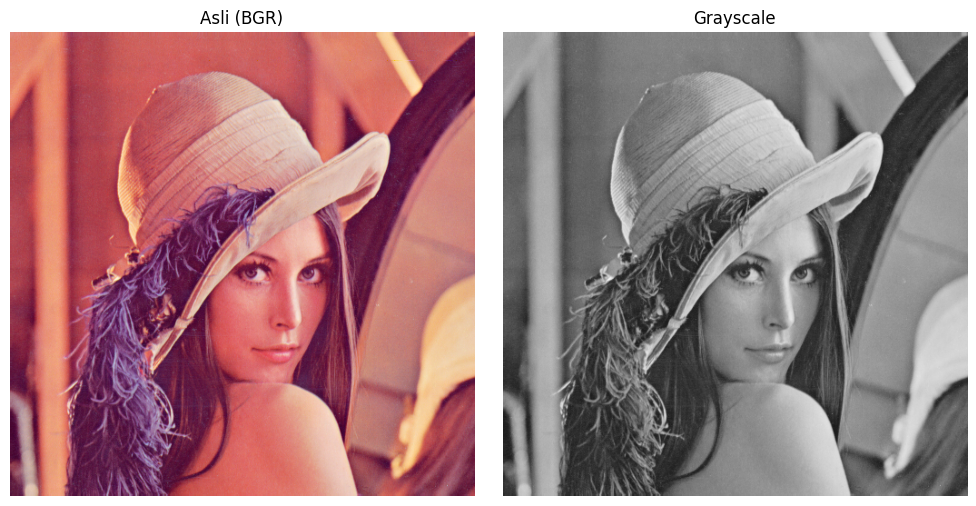

In [32]:
# Muat citra. Ubah daftar path sesuai lokasi file di Drive kamu.
CANDIDATE_PATHS = [
    "/content/drive/MyDrive/PCVK/Images/Lenna.png",
    "/content/drive/MyDrive/PCVK/Lenna.png",
    "/content/drive/MyDrive/PCVK/Images/mandrill.tiff",
    "/content/drive/MyDrive/PCVK/mandrill.tiff",
]

img = None
for p in CANDIDATE_PATHS:
    img = cv.imread(p)
    if img is not None:
        print("Citra dimuat dari:", p)
        break

if img is None:                                  # cadangan jika file Drive tidak ditemukan
    from skimage import data
    img = cv.cvtColor(data.astronaut(), cv.COLOR_RGB2BGR)
    print("File Drive tidak ditemukan, memakai citra cadangan (skimage.data.astronaut).")

img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
print("Ukuran citra:", img.shape)
show_side_by_side([img, img_gray], ["Asli (BGR)", "Grayscale"], figsize=(10, 5))

---
## Tugas 1 – Analisis: Mean Filter vs Median Filter pada Noise *Salt and Pepper*

### 1a. Tambahkan noise *Salt and Pepper* ke citra grayscale

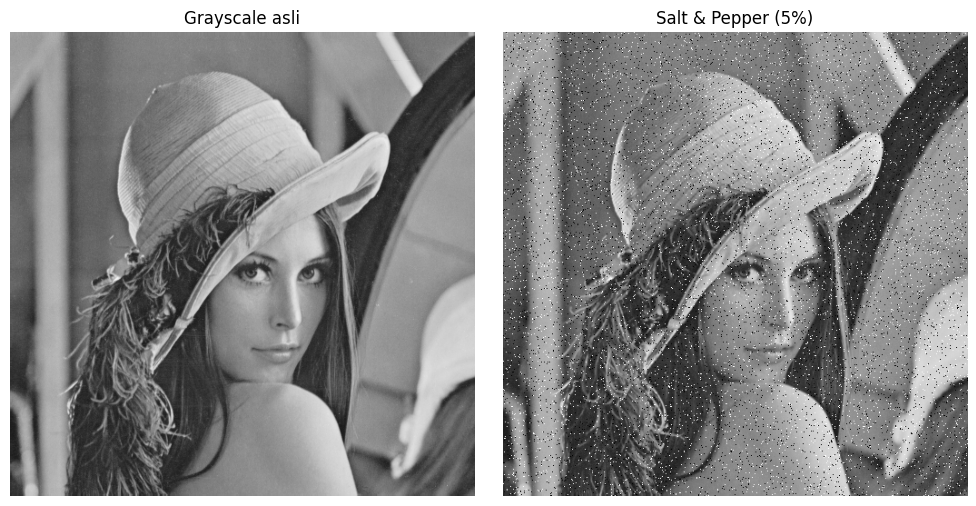

In [33]:
def add_salt_pepper(image, amount=0.05, salt_ratio=0.5, seed=42):
    """Tambah noise bintik putih (salt) & hitam (pepper).
    amount     : proporsi piksel yang terkena noise
    salt_ratio : porsi salt (putih) dari seluruh piksel ber-noise
    """
    rng = np.random.default_rng(seed)
    noisy = image.copy()
    n_noise = int(amount * image.size)
    n_salt = int(n_noise * salt_ratio)

    ys = rng.integers(0, image.shape[0], n_noise)
    xs = rng.integers(0, image.shape[1], n_noise)
    noisy[ys[:n_salt], xs[:n_salt]] = 255        # salt
    noisy[ys[n_salt:], xs[n_salt:]] = 0          # pepper
    return noisy

noisy = add_salt_pepper(img_gray, amount=0.05)
show_side_by_side([img_gray, noisy], ["Grayscale asli", "Salt & Pepper (5%)"], figsize=(10, 5))

### 1b. Terapkan Mean Filter (3×3) dan Median Filter (3×3)

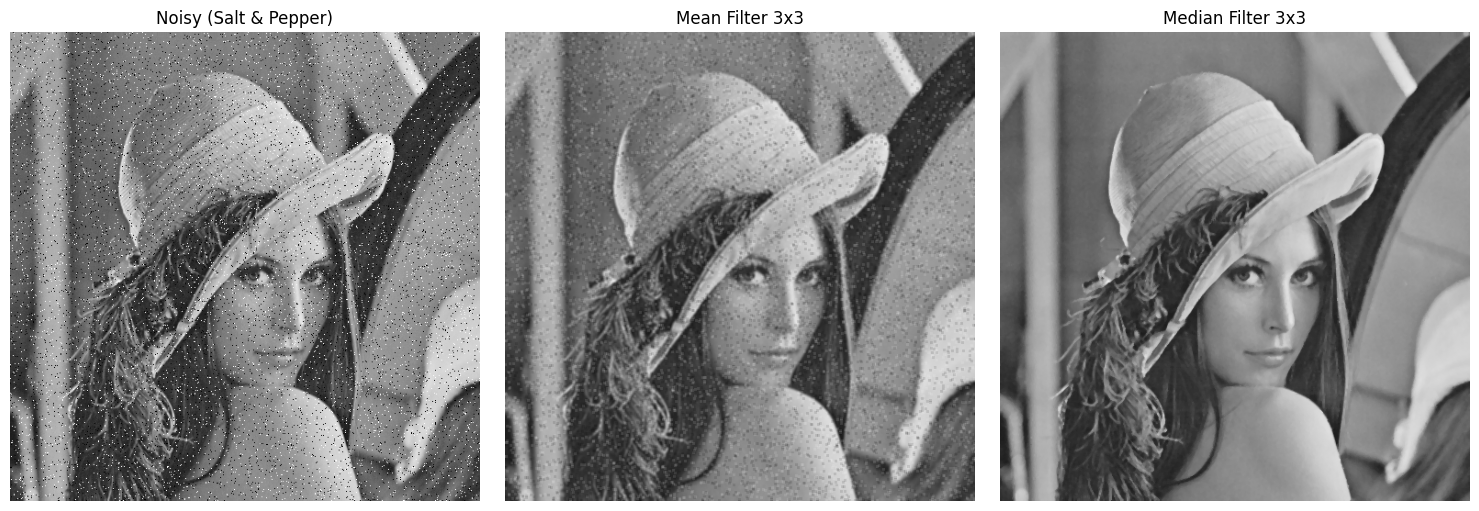

In [34]:
mean_f = cv.blur(noisy, (3, 3))          # Mean filter 3x3
median_f = cv.medianBlur(noisy, 3)       # Median filter 3x3

show_side_by_side([noisy, mean_f, median_f],
                  ["Noisy (Salt & Pepper)", "Mean Filter 3x3", "Median Filter 3x3"])

### 1c. Analisis visual dan kuantitatif

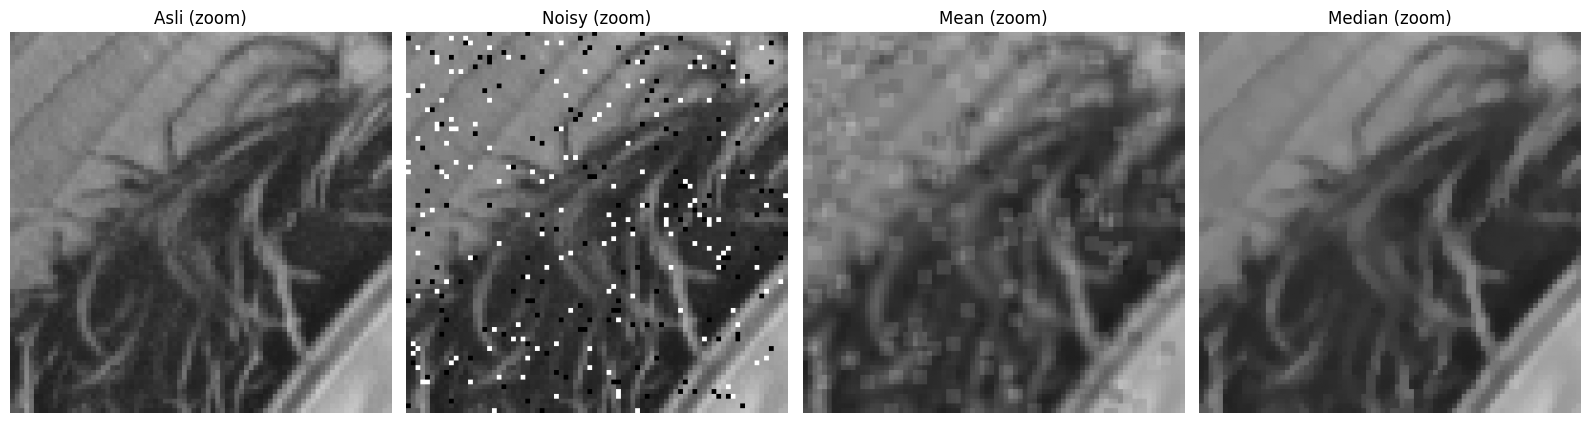

PSNR terhadap citra asli (dB, makin tinggi makin baik):
  Noisy         : 18.54
  Mean 3x3      : 26.77
  Median 3x3    : 34.87


In [35]:
# Perbesar bagian citra supaya perbedaannya jelas
h, w = img_gray.shape
y0, x0 = h // 3, w // 3
crop = lambda im: cv.resize(im[y0:y0 + 80, x0:x0 + 80], None, fx=4, fy=4,
                            interpolation=cv.INTER_NEAREST)

show_side_by_side([crop(img_gray), crop(noisy), crop(mean_f), crop(median_f)],
                  ["Asli (zoom)", "Noisy (zoom)", "Mean (zoom)", "Median (zoom)"], figsize=(16, 4.5))

print(f"PSNR terhadap citra asli (dB, makin tinggi makin baik):")
print(f"  Noisy         : {psnr(img_gray, noisy):.2f}")
print(f"  Mean 3x3      : {psnr(img_gray, mean_f):.2f}")
print(f"  Median 3x3    : {psnr(img_gray, median_f):.2f}")

### Kesimpulan Tugas 1
**Mengapa Median Filter jauh lebih bersih menghapus noise *Salt and Pepper* dibanding Mean Filter?**

- **Mean Filter** mengganti tiap piksel dengan *rata-rata* tetangganya. Piksel noise bernilai ekstrem (0 atau 255) ikut masuk hitungan, sehingga rata-ratanya tertarik ke arah nilai ekstrem itu. Noise tidak hilang, hanya **menyebar** menjadi bercak abu-abu yang samar, dan tepi objek ikut menjadi buram.
- **Median Filter** mengurutkan nilai piksel dalam jendela 3×3 lalu mengambil nilai **tengah**. Nilai noise (0 dan 255) selalu berada di ujung urutan, jadi **terbuang** dan tidak pernah terpilih sebagai median selama noise di jendela itu kurang dari separuh. Hasilnya piksel noise diganti dengan nilai yang wajar dari tetangganya.
- Median juga **lebih menjaga tepi** karena nilai hasilnya selalu berasal dari piksel yang benar-benar ada di jendela, bukan hasil perataan.
- Hasil kuantitatif (PSNR) di atas mendukung pengamatan visual: Median Filter memberi PSNR lebih tinggi daripada Mean Filter.

Median filter adalah filter **non-linear** (berbasis urutan), sedangkan mean filter **linear** (berbasis penjumlahan berbobot). Noise impulsif seperti *salt and pepper* adalah kasus yang paling cocok ditangani filter non-linear.

---
## Tugas 2 – Evaluasi: Ukuran Kernel Terbaik untuk *Sharpening*

### 2a. Buat kernel sharpening 3×3 dan 5×5

In [36]:
# Kernel 3x3 (jumlah elemen = 1, jadi kecerahan keseluruhan tidak berubah)
kernel_3x3 = np.array([[ 0, -1,  0],
                       [-1,  5, -1],
                       [ 0, -1,  0]], dtype=np.float32)

# Kernel 5x5 (jumlah elemen = 1)
kernel_5x5 = np.array([[-1, -1, -1, -1, -1],
                       [-1,  2,  2,  2, -1],
                       [-1,  2,  8,  2, -1],
                       [-1,  2,  2,  2, -1],
                       [-1, -1, -1, -1, -1]], dtype=np.float32) / 8.0

print("Kernel 3x3:\n", kernel_3x3, "\nJumlah:", kernel_3x3.sum())
print("\nKernel 5x5:\n", np.round(kernel_5x5, 3), "\nJumlah:", kernel_5x5.sum())

Kernel 3x3:
 [[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]] 
Jumlah: 1.0

Kernel 5x5:
 [[-0.125 -0.125 -0.125 -0.125 -0.125]
 [-0.125  0.25   0.25   0.25  -0.125]
 [-0.125  0.25   1.     0.25  -0.125]
 [-0.125  0.25   0.25   0.25  -0.125]
 [-0.125 -0.125 -0.125 -0.125 -0.125]] 
Jumlah: 1.0


### 2b. Terapkan pada citra yang sedikit buram (blurry)

Citra dibuat buram dengan Gaussian blur. Agar evaluasi *noise distortion* realistis, ditambahkan juga noise Gaussian ringan (σ = 5) seperti noise sensor kamera.

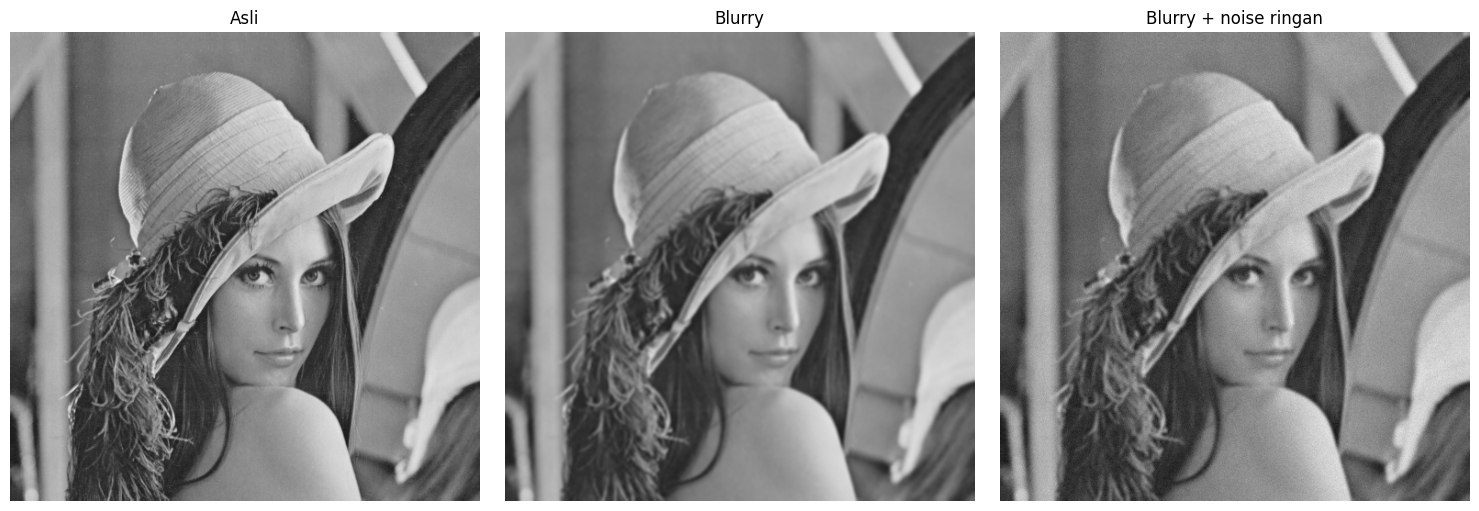

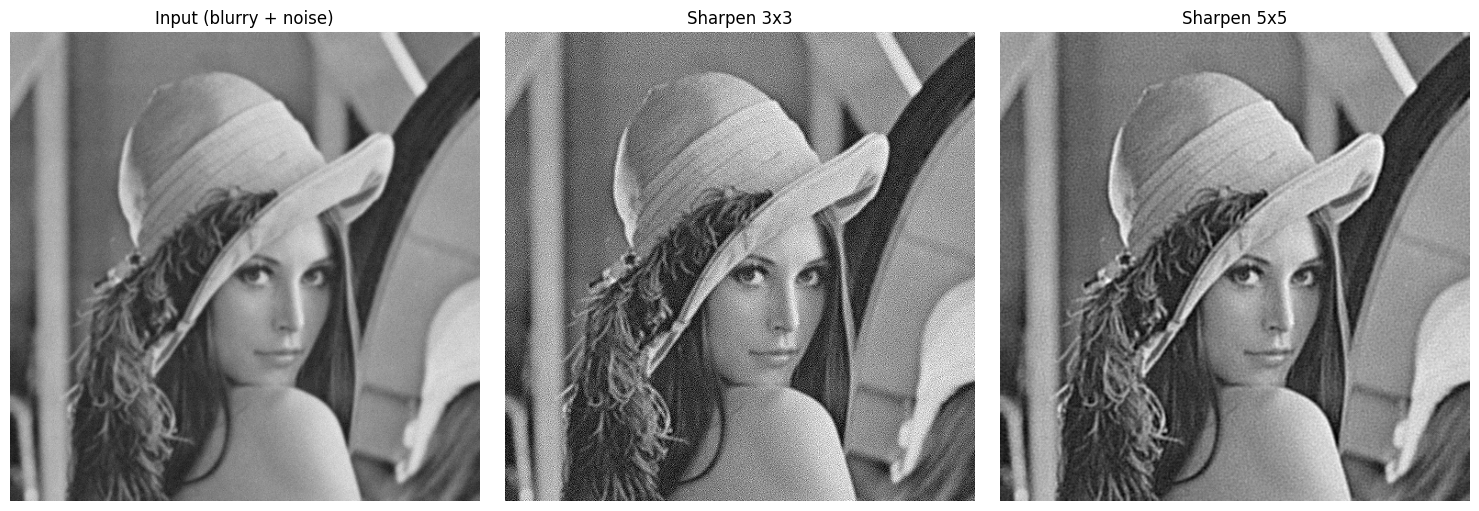

In [37]:
blurry = cv.GaussianBlur(img_gray, (5, 5), 1.5)           # citra buram (bersih)

rng = np.random.default_rng(0)
NOISE_SIGMA = 5
noise = rng.normal(0, NOISE_SIGMA, blurry.shape)
blurry_noisy = np.clip(blurry + noise, 0, 255).astype(np.uint8)   # buram + noise ringan

sharp_3_clean = cv.filter2D(blurry, -1, kernel_3x3)
sharp_5_clean = cv.filter2D(blurry, -1, kernel_5x5)
sharp_3 = cv.filter2D(blurry_noisy, -1, kernel_3x3)
sharp_5 = cv.filter2D(blurry_noisy, -1, kernel_5x5)

show_side_by_side([img_gray, blurry, blurry_noisy], ["Asli", "Blurry", "Blurry + noise ringan"])
show_side_by_side([blurry_noisy, sharp_3, sharp_5],
                  ["Input (blurry + noise)", "Sharpen 3x3", "Sharpen 5x5"])

### 2c. Evaluasi: kejelasan tepi vs *noise distortion*

In [38]:
# Kejelasan tepi diukur pada pipeline BERSIH (tanpa noise) supaya tidak tercampur noise.
# Noise distortion diukur dari seberapa besar noise input diperkuat oleh filter.
def noise_gain(sharp_noisy, sharp_clean):
    diff = sharp_noisy.astype(np.float64) - sharp_clean.astype(np.float64)
    return diff.std() / NOISE_SIGMA

print(f"{'Citra':<18}{'Tepi (Sobel)':>14}{'Detail (Lap.)':>15}{'Penguatan noise':>17}{'PSNR*':>10}")
print("-" * 74)
print(f"{'Citra asli':<18}{edge_strength(img_gray):>14.1f}{detail_sharpness(img_gray):>15.1f}{'-':>17}{'-':>10}")
print(f"{'Blurry (input)':<18}{edge_strength(blurry):>14.1f}{detail_sharpness(blurry):>15.1f}{1.0:>16.2f}x{psnr(img_gray, blurry_noisy):>8.1f}dB")
for name, clean, noisy_res in [("Sharpen 3x3", sharp_3_clean, sharp_3), ("Sharpen 5x5", sharp_5_clean, sharp_5)]:
    print(f"{name:<18}{edge_strength(clean):>14.1f}{detail_sharpness(clean):>15.1f}"
          f"{noise_gain(noisy_res, clean):>16.2f}x{psnr(img_gray, noisy_res):>8.1f}dB")

print("\nTepi (Sobel)  : makin besar = tepi makin tegas, diukur pada citra tanpa noise.")
print("Detail (Lap.) : makin besar = detail halus makin tajam, diukur pada citra tanpa noise.")
print("Penguatan noise: rasio simpangan baku noise sesudah/sebelum filter (makin kecil makin baik).")
print("PSNR*         : kemiripan citra HASIL (dari input ber-noise) terhadap citra asli.")

Citra               Tepi (Sobel)  Detail (Lap.)  Penguatan noise     PSNR*
--------------------------------------------------------------------------
Citra asli                  48.1          388.9                -         -
Blurry (input)              32.3           18.6            1.00x    29.4dB
Sharpen 3x3                 42.4          132.3            5.35x    19.4dB
Sharpen 5x5                 46.7           65.9            1.33x    29.2dB

Tepi (Sobel)  : makin besar = tepi makin tegas, diukur pada citra tanpa noise.
Detail (Lap.) : makin besar = detail halus makin tajam, diukur pada citra tanpa noise.
Penguatan noise: rasio simpangan baku noise sesudah/sebelum filter (makin kecil makin baik).
PSNR*         : kemiripan citra HASIL (dari input ber-noise) terhadap citra asli.


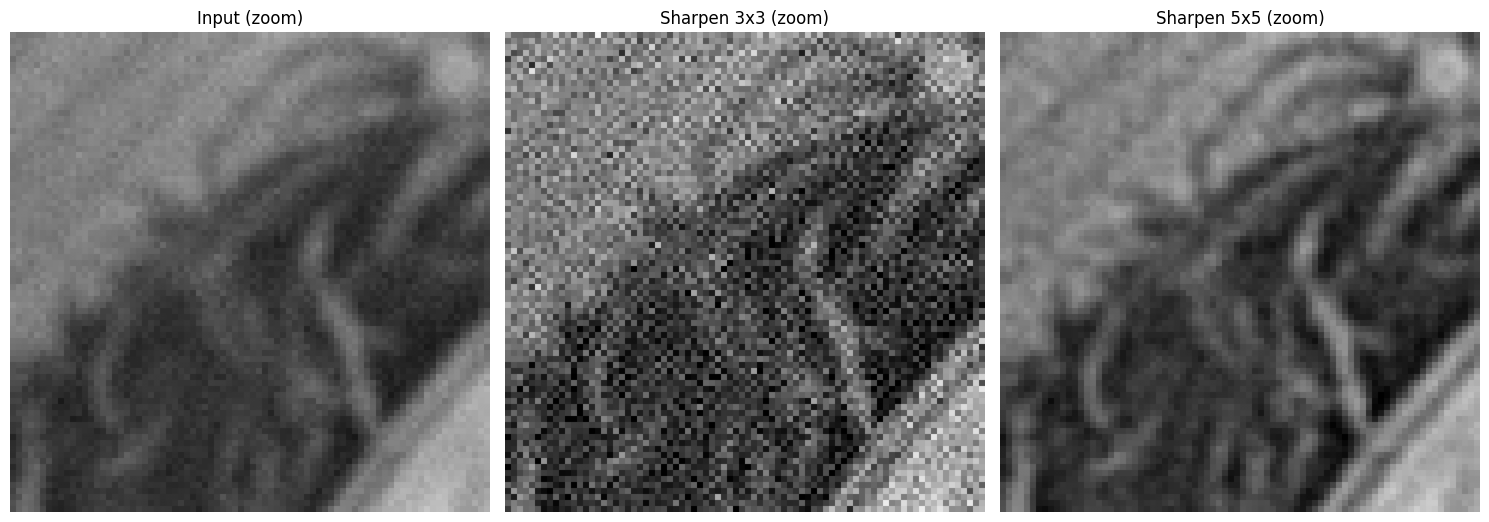

In [39]:
# Zoom pada area detail untuk membandingkan secara visual
y0, x0 = h // 3, w // 3
crop2 = lambda im: cv.resize(im[y0:y0 + 80, x0:x0 + 80], None, fx=4, fy=4,
                             interpolation=cv.INTER_NEAREST)
show_side_by_side([crop2(blurry_noisy), crop2(sharp_3), crop2(sharp_5)],
                  ["Input (zoom)", "Sharpen 3x3 (zoom)", "Sharpen 5x5 (zoom)"], figsize=(15, 5.5))

### Kesimpulan Tugas 2
| Aspek | Kernel 3×3 | Kernel 5×5 |
|---|---|---|
| Kejelasan tepi (Sobel) | Memulihkan tepi sebagian | Memulihkan tepi **lebih baik**, mendekati citra asli |
| Detail halus (Laplacian) | **Sangat tajam** (mengangkat frekuensi tinggi paling agresif) | Lebih moderat |
| Noise distortion | **Memperkuat noise ±5×**, noise berubah jadi butiran kasar | Hanya ±1,3×, noise hampir tidak berubah |
| Kualitas akhir (PSNR input ber-noise) | **Turun** di bawah citra input | Sedikit **naik** dari citra input |
| Biaya komputasi | 9 perkalian per piksel | 25 perkalian per piksel |

**Penjelasan:** penguatan noise sebuah kernel kira-kira sebesar akar jumlah kuadrat elemennya, yaitu √29 ≈ 5,4 untuk 3×3 dan √1,75 ≈ 1,3 untuk 5×5. Kernel 3×3 menaikkan gain frekuensi tinggi sampai 5× sehingga detail halus dan noise sama-sama meledak. Kernel 5×5 memusatkan penajaman di frekuensi menengah (area tepi yang jelas) dan hampir tidak menyentuh frekuensi tertinggi, tempat noise berada.

**Kernel paling optimal untuk sehari-hari: 5×5.** Foto nyata hampir selalu mengandung noise sensor, dan kernel 5×5 menegaskan tepi tanpa merusak citra dengan noise. Kernel 3×3 hanya layak dipakai pada citra yang benar-benar bersih (hasil render, tangkapan layar, scan) atau jika citra di-*denoise* dulu. Biaya komputasi 5×5 yang lebih besar tidak signifikan untuk penggunaan biasa.

*Catatan:* angka pada tabel bergantung pada citra yang dipakai. Jalankan ulang dengan citramu sendiri dan cek apakah polanya sama (3×3 unggul di detail, 5×5 unggul di penguatan noise).

---
## Tugas 3 – Kreasi: Filter Kartun Sederhana

### 3a. Fungsi `kartun(image)`
Tiga tahap:
1. **Penghalusan warna** dengan *Bilateral Filter* (meratakan area warna, tepi tetap terjaga).
2. **Deteksi garis tepi** dengan *Adaptive Thresholding* atau *Canny Edge*.
3. **Penggabungan** dengan operasi logika (`bitwise_and`) antara citra warna halus dan topeng tepi.

In [40]:
def kartun(image, metode_tepi="adaptive", iterasi_bilateral=3):
    """Efek kartun sederhana.

    image             : citra BGR
    metode_tepi       : 'adaptive' (Adaptive Thresholding) atau 'canny' (Canny Edge)
    iterasi_bilateral : berapa kali bilateral filter diulang (makin banyak = warna makin rata)
    """
    # 1. Penghalusan warna: bilateral filter diulang agar area warna menjadi rata
    warna = image.copy()
    for _ in range(iterasi_bilateral):
        warna = cv.bilateralFilter(warna, d=9, sigmaColor=75, sigmaSpace=75)

    # 2. Deteksi garis tepi
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray = cv.medianBlur(gray, 7)                 # kurangi noise sebelum deteksi tepi
    if metode_tepi == "adaptive":
        # garis tepi = piksel hitam, area lain putih
        tepi = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C,
                                    cv.THRESH_BINARY, blockSize=9, C=9)
    elif metode_tepi == "canny":
        canny = cv.Canny(gray, 80, 160)           # tepi = putih
        tepi = cv.bitwise_not(canny)              # dibalik: tepi hitam, area lain putih
    else:
        raise ValueError("metode_tepi harus 'adaptive' atau 'canny'")

    # 3. Penggabungan: operasi logika AND (piksel tepi hitam menimpa warna)
    tepi_bgr = cv.cvtColor(tepi, cv.COLOR_GRAY2BGR)
    return cv.bitwise_and(warna, tepi_bgr)

### 3b. Tampilkan citra asli dengan citra efek kartun bersebelahan

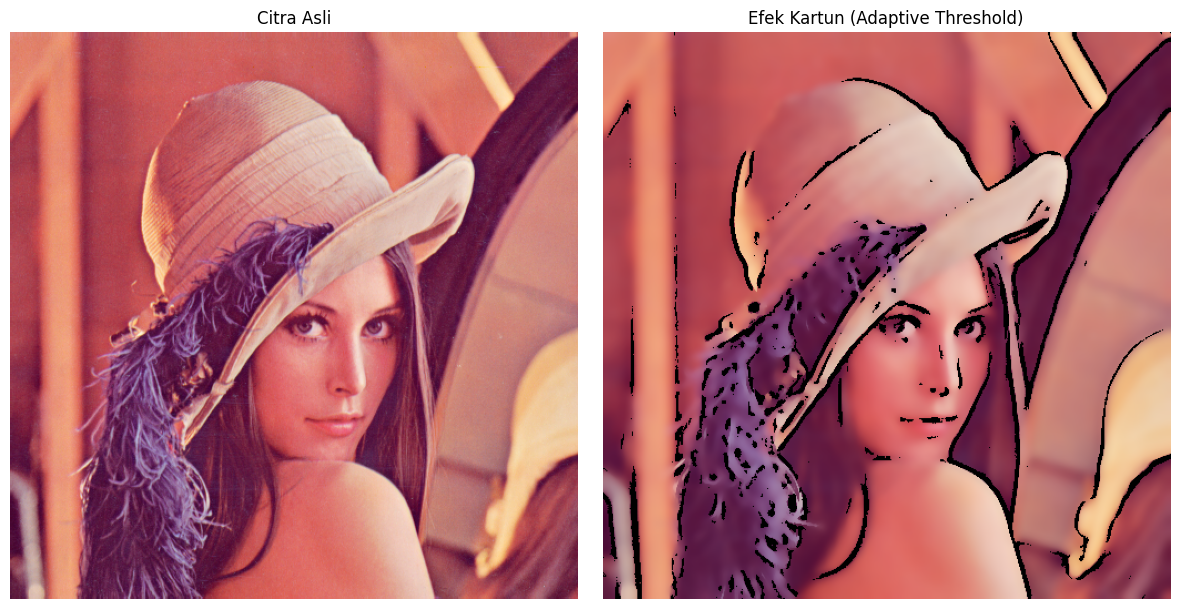

In [41]:
hasil_kartun = kartun(img, metode_tepi="adaptive")
show_side_by_side([img, hasil_kartun], ["Citra Asli", "Efek Kartun (Adaptive Threshold)"], figsize=(12, 6))

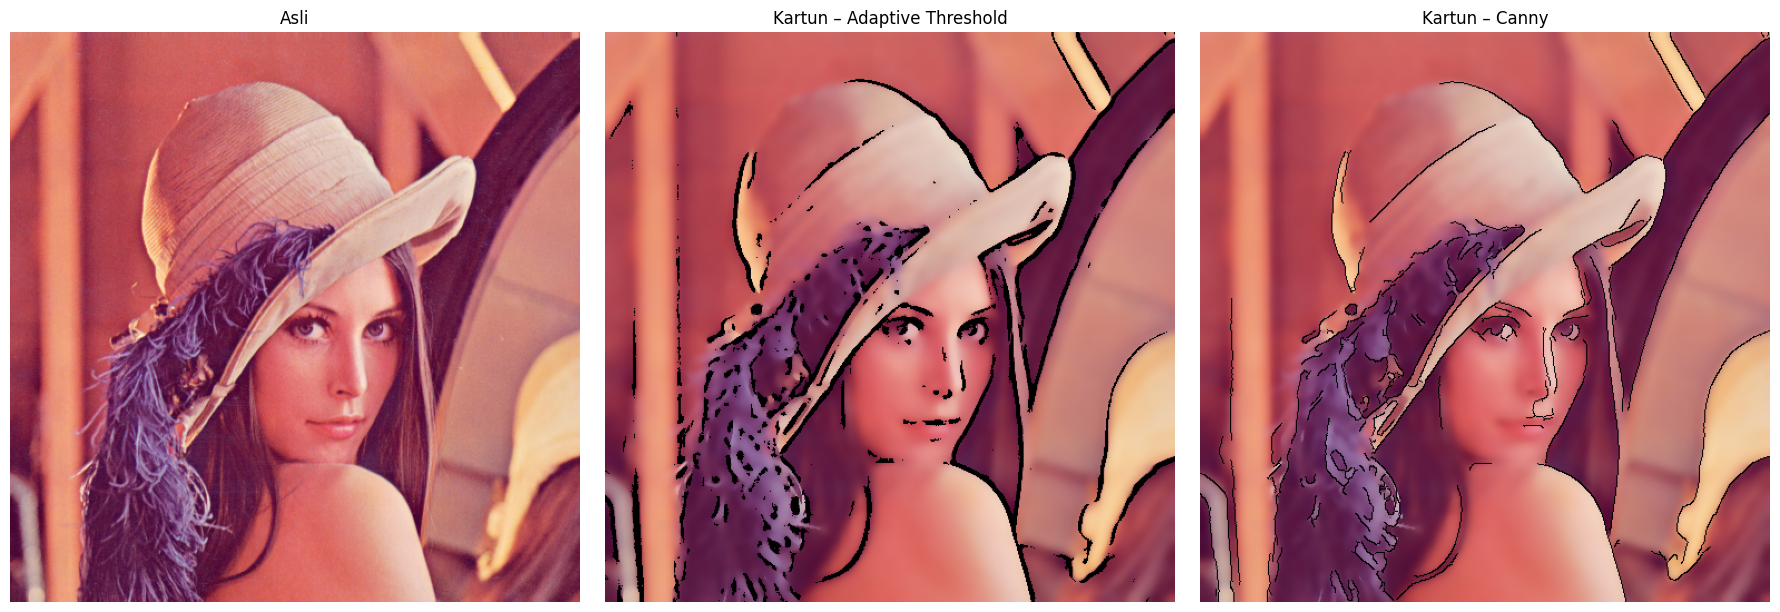

In [42]:
# Bandingkan dua metode deteksi tepi
kartun_adaptive = kartun(img, metode_tepi="adaptive")
kartun_canny = kartun(img, metode_tepi="canny")
show_side_by_side([img, kartun_adaptive, kartun_canny],
                  ["Asli", "Kartun – Adaptive Threshold", "Kartun – Canny"], figsize=(18, 6))

### Catatan Tugas 3
- **Bilateral Filter** menghaluskan warna tanpa menghapus tepi (berbeda dengan Gaussian blur yang membuat tepi ikut kabur), sehingga area warna menjadi rata seperti gambar kartun.
- **Adaptive Thresholding** menghitung ambang per area kecil, sehingga garis tepinya tebal dan konsisten seperti sketsa. **Canny** menghasilkan garis yang lebih tipis dan lebih sensitif terhadap detail.
- **Penggabungan** memakai `bitwise_and`: piksel topeng putih (255) meneruskan warna aslinya, piksel hitam (0) menjadi garis hitam.
- Parameter yang bisa diutak-atik: `iterasi_bilateral` (kerataan warna), `blockSize` dan `C` (ketebalan garis adaptive), serta ambang Canny.